# Nonlinear optimization

## Optimum power for a set of $m$ lamps illuminating a set of $n$ flat patches to best approach a target illumination

Consider $m$ lamps illuminating $n$ (small flat) patches. The illumination intensity $I_k$ at the $k$-th patch depends linearly on the lamp powers $p_j$ as:
$$
I_k = \sum\limits_{j=1}^m a_{k,j}p_j, \quad \text{with} \quad a_{k,j} = r^{-2}_{k,j}\max\{\cos(\theta_{k,j}, 0\},
$$
where $r_{k,j}$ is the length of the vector $\mathbf{r}_{k,j}$ connecting the center of the $k$-th patch to the position of the $m$-th lamp and $\theta_{k,j}$ is the angle between the patch normal vector $\mathbf{n}_{k}$ and $\mathbf{r}_{k,j}$. See the Convex Optimization book slides for more details.

The proposed problem is to achieve a desired illumination $I_{des}$ with bounded lamp powers ($p_{max}$), i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert \log(I_k) - \log(I_{des})\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$


### Suboptimally solve the problem using according to the following approaches:

1. Using uniform power, i.e., $p_j = p, 0 \leq p \leq p_{max}$.
2. Using least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2$, and rounding $p_j$ as $p_j = \max\{0, \min\{p_j, p_{max}\}\}$.
3. Using weighted least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2 + \sum\limits_{j=1}^m w_j (p_j - p_{max}/2)^2$ and iteratively adjusting the weights $w_j$ until $0 \leq p \leq p_{max}, \forall j$.
4. Using linear programming, i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert I_k - I_{des}\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$

### Solve the problem optimally using convex optimization

For this goal, consider the equivalent convex problem
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}h(I_k/I_{des}) \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m,
\end{align*}
$$
where $h(u) = \max\{u, 1/u\}$.


# Scenario generation function

We begin the problem by creating the scenario with a certain number of patches (numPatches) and a certain amount of lamps (numLamps).

In [2]:
def generate_scenario(numLamps : int, numPatches : int):
    # Preallocate the patch and lamp positions
    patchPos = np.zeros((numPatches+1, 2), dtype=float)
    lampPos = np.zeros((numLamps, 2), dtype=float)

    # Generate patches extreme points
    x_patches = 1 + 3 * np.random.rand(numPatches+1)
    x_patches = np.cumsum(x_patches)
    y_patches = 2 + 1 * np.random.rand(numPatches+1)
    patchPos[:, 0] = x_patches
    patchPos[:, 1] = y_patches

    # Generate lamp extreme points
    # x_lamps = 1 + 5 * np.random.rand(numLamps)
    # x_lamps = np.cumsum(x_lamps)
    x_lamps = min(x_patches) + (max(x_patches) - min(x_patches)) * np.random.rand(numLamps)
    y_lamps = 6 + 1 * np.random.rand(numLamps)
    lampPos[:, 0] = x_lamps
    lampPos[:, 1] = y_lamps

    # return
    return patchPos, lampPos

We implement the objective function as

In [3]:
def objective_function(A : np.ndarray, p : np.ndarray, Ides : float)->float:
    '''
    objective_function(A : np.ndarray, p : np.ndarray, Ides : float)->float

    Description: Original objective function

    Input:
        A : matrix whose element [A]_{k,j} represents the coefficient related to
            the k-th patch and the j-th lamp
        p : vector whose j-th element [p]_j represents the power of the j-th lamp
        Ides: scalar that represents the desired illumination intensity

    Output:
        return the objective function of the main optimization problem
    '''
    return np.max(np.abs(np.log10(A @ p) - np.log10(Ides)))

# Set simulation parameters and generate scenario in a figure

Now we set the simulation parameters and create a representation of the scenario

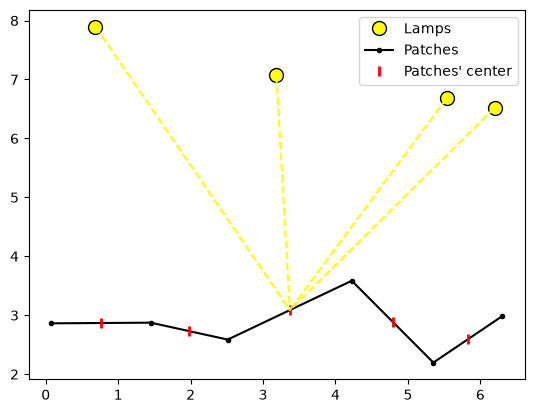

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

# Seed
# np.random.seed(10)

'''Simulation parameters'''
showFig = True;          # Figure
numLamps = 4;           # Number of lamps 4
numPatches = 5;         # Number of patches 5
maxPwr = 1;              # Maximum power [W]
desiredillum = 0.01;     # Desired illumination

# Position of the lamps and the extreme points of the patches in real matrices
# We assume that the lamps will be higher than the patches
lampPos = np.array([[0.6838, 7.8976], [3.1835, 7.0690], [5.5327, 6.6806], [6.1963, 6.5203]])
patchPos = np.array([[0.0762, 2.8621], [1.4506, 2.8733], [2.5122, 2.5864], [4.2246, 3.5846], [5.3512, 2.1960], [6.3013, 2.9838]])
# patchPos, lampPos = generate_scenario(numLamps, numPatches)

# Position of the lamps and the extreme points of the patches in complex vectors
lampPos = lampPos[:, 0] + 1j * lampPos[:, 1]
patchPos = patchPos[:, 0] + 1j * patchPos[:, 1]

# Get the center of each patch
patchCenter = (patchPos[0:-1] + patchPos[1:]) / 2

# Obtain the normal versors to the patches
patch_diff_vector = patchPos[1:]-patchPos[0:-1]
normal_vectors = -np.imag(patch_diff_vector) + 1j * np.real(patch_diff_vector)
normal_versors = normal_vectors / np.abs(normal_vectors)    # Note that each vector is represented by a complex number

# Obtain the distance "vectors" represented by a complex number
mt_coeff = np.zeros((len(patchCenter), len(lampPos)), float)
for c1 in range(len(patchCenter)):
    for c2 in range(len(lampPos)):
        dist_vector = lampPos[c2] - patchCenter[c1]
        # We assume lamps in higher positions than patches
        ang = np.real(dist_vector * np.conjugate(normal_versors[c1])) / np.abs(dist_vector)
        mt_coeff[c1, c2] = (np.abs(dist_vector)**(-2)) * max(ang, 0)

''' Plot of the scenario '''
if showFig:
    # Plot the lamps
    plt.plot(np.real(lampPos), np.imag(lampPos), 'o', color="yellow", markersize = 10, markeredgecolor = 'k', label = "Lamps")

    # Plot the patches
    plt.plot(np.real(patchPos), np.imag(patchPos), 'o-', color = 'k', markersize = 3, label = "Patches")

    # Plot the center of the patches
    plt.plot(np.real(patchCenter), np.imag(patchCenter), '|', color = 'r', markersize = 7, markeredgewidth=2, label = "Patches' center")

    # Plot the lamps rays to a certain patch
    for c1 in range(len(lampPos)):
        plt.plot([np.real(lampPos[c1]), np.real(patchCenter[2])], [np.imag(lampPos[c1]), np.imag(patchCenter[2])], '--', color = "yellow")

    plt.legend()
    plt.show

# 1) Uniform power solution
Since the $m$-th lamp power $p_m$ must satisfy the power constraint $0 \leq p_m \leq p_{\text{max}}$, we design the uniform power solution $p_m = p_{\text{uni}}$ for every $m \in \{1, 2, \cdots, M\}$, where $0 \leq p_{\text{uni}} \leq p_{\text{max}}$. This means that this approach does not care to minimize the objective function, but only satisfies the set of possible solutions, which is the feasible set of the optimization problem. 

Let $f(\mathbf{p}) = \underset{k=1, 2, \ldots, n}{\max}\vert \log(I_k) - \log(I_{des})\vert$ be the true optimization function and let  $\mathbf{p} = p_{\text{uni}} \mathbf{1}_{M}$. The idea is to begin $p_{\text{uni}}$ with an initial real positive number greater than $0$ and less than $p_{\text{max}}$, and store in some data structure the result obtained when we apply the powers to $f(\mathbf{p})$. Then, we increase slightly $p_{\text{uni}}$ and store the new value. After we increase $p_{\text{uni}}$ until reach $p_{\text{max}}$, we compare the stored obtained values and get the $p_{\text{uni}}$ that minimized more the objective function.

In [5]:
def uniform_power(numLamps, maxPwr, mt_coeff, desiredillum):

    # Generate powers
    vt_powers = np.arange(1e-6, maxPwr, 0.001)

    # Objective values stored in a vector
    vt_obj = np.zeros((len(vt_powers),), dtype=float)

    # Store the last value
    store_last_obj_function_value = np.inf

    # Iterate over the powers
    for k in range(len(vt_powers)):

        # Create the lamp power vector
        p = vt_powers[k] * np.ones(numLamps)

        # Compute the objective value
        vt_obj[k] = objective_function(mt_coeff, p, desiredillum)

        # # If the current objective function is greater than the last value,
        # # we can stop the loop here, because we know (via inspection in a plot)
        # # that the stored objective values has one minimum. Then, if the nest
        # # value is greater than the past,this means that last value is the
        # # minimum
        # if store_last_obj_function_value >= vt_obj[k]:
        #     store_last_obj_function_value = vt_obj[k]
        # else:
        #     idx = k - 1
        #     break

    # Get the index of the minimum objective value
    idx = np.argmin(vt_obj)

    # The optimization variable is then
    p_uniform = vt_powers[idx] * np.ones(numLamps)

    # Return
    return p_uniform, vt_obj[idx], vt_obj

Now with the data and the functions, we find the uniform power solution and we show a plot representing relation $f(p_{\text{uni}} \mathbf{1}_M) \times p_{\text{uni}}$.

The solution p: [0.080001 0.080001 0.080001 0.080001]
The objective value obtained: 0.07471243100861891


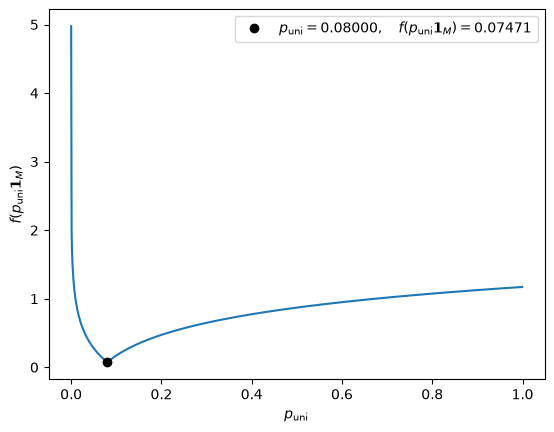

In [6]:
# Uniform power solution
power_uniform, obj_uniform_power, vt = uniform_power(numLamps, maxPwr, mt_coeff, desiredillum)
print("The solution p:", power_uniform)
print("The objective value obtained:", obj_uniform_power)

# f-string marking the solution point for the uniform power solution
s = (
    f'$p_{{\\text{{uni}}}} = {power_uniform[0]:.5f},'
    f'\\quad f(p_{{\\text{{uni}}}} \\mathbf{{1}}_M) = {obj_uniform_power:.5f}$'
)

plt.plot(np.arange(1e-6, maxPwr, 0.001), vt, '-')
plt.plot(power_uniform[0], obj_uniform_power, 'ko', label=s)
plt.legend()
plt.xlabel('$p_{\\text{uni}}$')
plt.ylabel('$f(p_{\\text{uni}} \\mathbf{1}_M)$')
plt.show()

# 2 Least squares
## 2.1 Least squares with a heuristic to the range of the lamps' powers
The least squares approach help us to minimize the variance of the illumination intensity of the lamps with respect to the desired illumination. That is why we would like to minimize $ \sum\limits_{k=1}^n (I_k - I_{des})^2$. Notice, however, that this approach does not include the constraint related to the range of the powers. So, one way to solve this issue is to force $p_j \in [0, p_{\text{max}}]$, and this is basically written as p_j = $\max\{0, \min\{p_j, p_{max}\}\}$. So, when $p_j > p_{\text{max}}$, we let $p_j = p_{\text{max}}$, and when $p_j < 0$, we say that $p_j = 0$.

Now we need to reformulate the least squares objective function, so we can get a more appropriate formulation. Notice that we can think $I_k$ as the $k$-th element of the vector $\mathbf{A}\mathbf{p}$, where, $\mathbf{A} \in \mathbb{R}^{n \times m}$ and $[\mathbf{A}]_{k,j} = a_{k,j}$. Then,
\begin{align}
\left[I_1 - I_{des}, \, I_2 - I_{des}, \, \cdots, \, I_n - I_{des} \right] &= \left[I_1, \, I_2, \, \cdots, \, I_n \right] - I_{des} \mathbf{1}, \\
&= \mathbf{A}\mathbf{p} - I_{des} \mathbf{1}
\end{align}
Thus, we rewrite:
\begin{align}
\sum\limits_{k=1}^n (I_k - I_{des})^2 &= \lVert \mathbf{A}\mathbf{p} - I_{des} \mathbf{1} \rVert_{2}^{2}.
\end{align}
The exact or the approximate solution that minimizes the objective function is  $\mathbf{p} = I_{des} \mathbf{A}^{\dagger} \mathbf{1}$. Note that we do not know if $[\mathbf{p}]_k$ is non-negative or is bounded by $p_{\text{max}}$. So, we adjust the solution, so we can have  a feasible solution to the optimization problem. Then, $p_k =\max\{0, \min\{[I_{des} \mathbf{A}^{\dagger} \mathbf{1}]_k, p_{max}\}\}$, for every $k$-th lamp.

In [7]:
# Solution with filtering steps to satisfy the feasibility conditions
power_least_squares = desiredillum * np.linalg.pinv(mt_coeff) @ np.ones(numPatches)
power_least_squares[power_least_squares > maxPwr] = maxPwr
power_least_squares[power_least_squares < 0] = 0
obj_least_squares = objective_function(mt_coeff, power_least_squares, desiredillum)

print("The solution p:", power_least_squares)
print("The objective value obtained:", obj_least_squares)

The solution p: [0.14080514 0.11888099 0.         0.47087677]
The objective value obtained: 0.45949110738752696


## 2.2 Quadratic programming
Notice that the least squares objetive function is a quadratic function with respect to the vector of the lamps' power $\mathbf{p} \in \mathbb{R}^{m}$. The last approach is kind of easy because it has a closed-form solution. Although, the price to pay, is that we needed to filter the solution, to obtain a feasible solution. Now, with quadratic programming, this is not an issue anymore, because we can include the linear constraints $0 \leq p_j \leq p_{\text{max}}, \, j \in \{1,2, \cdots, m\}$ which are linear. Using cvxpy, the solution can be easily obtained.

In [8]:
# Define the optimization variable
x = cp.Variable(numLamps)

# Define the objective function
objective = cp.sum_squares(mt_coeff @ x - desiredillum * np.ones(numPatches))

# Non-negativity contraints
constraint_lower_bound = [x >= 0]

# Maximum power contraints
constraint_upper_bound = [x <= maxPwr]

# Mesh the constraints
constraints = constraint_lower_bound
constraints += constraint_upper_bound

# Define the optimization problem
prob = cp.Problem(cp.Minimize(objective), constraints)

# Solve the optimization problem
prob.solve()

# Get the solution and transform to a np.ndarray
power_least_squares_cvxpy = np.array(x.value)

# Get the result of the original objective with the obtained solution
obj_least_squares_cvxpy = objective_function(mt_coeff, power_least_squares_cvxpy, desiredillum)

print("The solution p:", power_least_squares_cvxpy)
print("The objective value obtained:", obj_least_squares_cvxpy)

The solution p: [1.90568045e-01 5.32518875e-03 2.85227968e-19 1.61080328e-01]
The objective value obtained: 0.04044573144251662


# 3 Linear programming

The objective function is given by $f(\mathbf{p}) = \underset{i=1,2,\cdots,m}{\max} \vert I_k - I_{\text{des}} \vert$. We can use the epigraph formulation. So, we introduce the real variable $t$, such that the equivalent formulation of the optimization problem is:

$$
\begin{align*}
    \underset{\mathbf{p}, t} \min \quad t \\
    \text{s. t.} \quad &\vert I_k - I_{\text{des}} \vert \leq t,  \quad k \in \{1, \cdots, n\}, \\
    &-\mathbf{p} \leq \mathbf{0}_m, \\
    &\mathbf{p} \leq p_{\text{max}} \mathbf{1}_m
\end{align*}
$$

From previous formulations, we know that $I_k =  \sum\limits_{j=1}^m a_{k,j}p_j$ can be rewritten as the dot product between the coefficients vector $\mathbf{a}_k = \left[a_{k,1}, \cdots, a_{k,m} \right]^T$ and the vector of power coefficients $\mathbf{p} = \left[p_1, \cdots, p_m \right]^T$ which give us $I_k = \mathbf{a}_k^T \mathbf{p}$. Furthemore, notice that the new absolute value constraint can be decomposed in
$$
\begin{equation}
    \begin{aligned}
        & -t \leq I_k - I_{\text{des}} \leq t,  \quad k \in \{1, \cdots, n\},  \\
        & -t \leq  \mathbf{a}_k^T \mathbf{p} - I_{\text{des}} \leq t,  \quad k \in \{1, \cdots, n\}, \\
        & -t \mathbf{1}_{n} \leq \mathbf{A} \mathbf{p} - I_{\text{des}} \mathbf{1}_n \leq t \mathbf{1}_n.
    \end{aligned}
\end{equation}
$$
We want to write the optimization problem in the standard form. So we introduce the new optimization variable $\mathbf{x} \in \mathbb{R}^{m+1}$, such that, $\mathbf{x} = \left[\mathbf{p}^T, t \right]^T$. Then, the objective function can be rewritten as: $t = \mathbf{e}_{m+1}^T \mathbf{x}$, where $\mathbf{e}_{i} = \left[\underset{1}{0}, \cdots, \underset{i}{1}, \cdots, \underset{m+1}{0} \right]$. Then, the constraints are:
$$
\begin{align*}
    \mathbf{A} \mathbf{p} - t \mathbf{1}_n  \leq I_{\text{des}} \mathbf{1}_n,\\
    -\mathbf{A} \mathbf{p} - t \mathbf{1}_n \leq -I_{\text{des}} \mathbf{1}_n,\\
    -\mathbf{p} \leq \mathbf{0}_m, \\
    \mathbf{p} \leq p_{\text{max}} \mathbf{1}_m
\end{align*}
$$
which can be rewritten as
$$
\begin{align*}
    \left[\mathbf{A}, \, -\mathbf{1}_n \right] \mathbf{x} \leq I_{\text{des}} \mathbf{1}_n,\\
    \left[-\mathbf{A}, \, -\mathbf{1}_n \right] \mathbf{x} \leq -I_{\text{des}} \mathbf{1}_n,\\
    \left[-\mathbf{I}_m, \, \mathbf{0}_m \right] \mathbf{x} \leq \mathbf{0}_m, \\
    \left[\mathbf{I}_m, \, \mathbf{0}_m \right] \mathbf{x} \leq p_{\text{max}} \mathbf{1}_m
\end{align*}
$$
we can stack all this inequalities and obtain
$$
\begin{equation*}
    \underbrace{\begin{bmatrix}
        \mathbf{A} & -\mathbf{1}_n \\
        -\mathbf{A} & -\mathbf{1}_n \\
        -\mathbf{I}_m & \mathbf{0}_m \\
        \mathbf{I}_m & \mathbf{0}_m \\
    \end{bmatrix}}_{2(n+m) \times (m+1)} \mathbf{x} = \begin{bmatrix}  I_{\text{des}} \mathbf{1}_n \\ -I_{\text{des}} \mathbf{1}_n \\ \mathbf{0}_m \\ p_{\text{max}} \mathbf{1}_m \end{bmatrix}
\end{equation*}
$$
Therefore the reformulated optimization problem is:
$$
\begin{align*}
    \underset{\mathbf{x}}{\min} \, \mathbf{e}_{m+1}^T \mathbf{x} \\
    \text{s. t.} \quad & \begin{bmatrix}
        \mathbf{A} & -\mathbf{1}_n \\
        -\mathbf{A} & -\mathbf{1}_n \\
        -\mathbf{I}_m & \mathbf{0}_m \\
        \mathbf{I}_m & \mathbf{0}_m \\
    \end{bmatrix} \mathbf{x} \leq \begin{bmatrix}  I_{\text{des}} \mathbf{1}_n \\ -I_{\text{des}} \mathbf{1}_n \\ \mathbf{0}_m \\ p_{\text{max}} \mathbf{1}_m \end{bmatrix}
\end{align*}
$$

In [18]:
def linear_programming(A, Ides, pmax):

    # Get the number of patches and lamps
    numPatches, numLamps = A.shape

    # Create the column vectors
    ones_n = np.ones(numPatches).reshape(-1,1)
    zeros_m = np.zeros((numLamps, 1), dtype=float)
    ones_m = np.ones(numLamps).reshape(-1,1)
    e = np.zeros((numLamps+1, 1), dtype=float)
    e[-1] = 1

    # Create the identity matrix m x m
    Im = np.eye(numLamps)

    # Create the rows of the matrix B
    B1 = np.hstack((A, -ones_n))
    B2 = np.hstack((-A, -ones_n))
    B3 = np.hstack((-Im, zeros_m))
    B4 = np.hstack((Im, zeros_m))

    # Stack the rows
    B5 = np.vstack((B1, B2))
    B6 = np.vstack((B3, B4))

    # Last stack (We can do better... but for now, lets left like this)
    B = np.vstack((B5, B6))
    
    # Create vector c
    c = np.zeros(2*(numPatches+numLamps), dtype=float)
    c[0:numPatches] = Ides
    c[numPatches:2*numPatches] = -Ides
    c[2*numPatches + numLamps:2 * (numPatches+numLamps)] = pmax

    # Create the optimization variable
    x = cp.Variable(numLamps+1)

    # Objective function
    f = e.T @ x

    # Constraint
    constraint = [B @ x <= c]

    # Problem
    prob = cp.Problem(cp.Minimize(f), constraint)

    # Solve the problem
    prob.solve()

    # Get the status of the solver
    status = prob.status
    
    # Get the obtained powers and objective function value of the linear problem
    p = np.array(x.value)
    p = p[:-1]
    t = p[-1]

    # Get the result of the original objective with the obtained solution
    obj_value = objective_function(A, p, Ides)

    return status, p, obj_value, t

status, p_lp, obj_value, t = linear_programming(mt_coeff, desiredillum, maxPwr)    

print("status: ", status)
print("p = ", p_lp)
print("t = ", t)
print("obj. value = ", obj_value)

status:  optimal
p =  [1.65128248e-01 1.89139158e-02 3.81258077e-08 1.55957696e-01]
t =  0.15595769648234273
obj. value =  0.03505558288244437


# 4 Convex
We can construct this function as an epigraph. So, applying the epigraph we get
$$
\begin{align*}
    \underset{\mathbf{p}, t}{\min} \, t \\
    \text{s. t.} \quad & h\left( \frac{I_k}{I_{\text{des}}} \right) \leq t, \\
    & \mathbf{0} \leq \mathbf{p} \leq p_{\text{max}} \mathbf{1}
\end{align*}
$$
which is
$$
\begin{align*}
    \underset{\mathbf{p}, t}{\min} \, t \\
    \text{s. t.} \quad & \max\left( \frac{I_k}{I_{\text{des}}}, \frac{I_{\text{des}}}{I_k} \right) \leq t, \\
    & \mathbf{0} \leq \mathbf{p} \leq p_{\text{max}} \mathbf{1}
\end{align*}
$$
since the maximum must be less or equal than $t$, then,
$$
\begin{align*}
    \underset{\mathbf{p}, t}{\min} \, t \\
    \text{s. t.} \quad & \frac{I_k}{I_{\text{des}}} \leq t, \, k \in \{1,2,\cdots,n\},\\
    &  \frac{I_{\text{des}}}{I_k} \leq t, \, k \in \{1,2,\cdots,n\}\\
    & \mathbf{0} \leq \mathbf{p} \leq p_{\text{max}} \mathbf{1},\\
    & t > 0
\end{align*}
$$
now we isolate the constraints and obtain the left hand side terms
$$
\begin{align*}
    \underset{\mathbf{p}, t}{\min} \, t \\
    \text{s. t.} \quad & I_k - I_{\text{des}} t \leq 0, \, k \in \{1,2,\cdots,n\},\\
    &  -I_k + \frac{I_{\text{des}}}{t} \leq 0, \, k \in \{1,2,\cdots,n\}\\
    & \mathbf{0} \leq \mathbf{p} \leq p_{\text{max}} \mathbf{1}, \\
    & t > 0
\end{align*}
$$
Again, using the expression that $[I_1, I_2, \cdots, I_n]^T = \mathbf{A}\mathbf{p}$, we obtain the new formulation
$$
\begin{align*}
    \underset{\mathbf{p}, t}{\min} \, t \\
    \text{s. t.} \quad & \mathbf{A}\mathbf{p} - I_{\text{des}} t \mathbf{1} \leq \mathbf{0}, \\
    &  -\mathbf{A}\mathbf{p} + \frac{I_{\text{des}}}{t} \mathbf{1} \leq \mathbf{0}, \\
    & \mathbf{0} \leq \mathbf{p} \leq p_{\text{max}} \mathbf{1}, \\
    & t > 0
\end{align*}
$$
If we want to include the constraint "no more than half of the total power is in any k lamps", we just need to compute half of the total power which is $(1/2) \sum_{j=1}^m p_j$. And estabilish the set of $q$ lamps which is $\mathcal{S}_q$. So there are $C_{q}^m$ set configurations. So for example, if we have the set 3 lamps and $q=2$, we will have the following constraint:
$$
\begin{align*}
    \begin{bmatrix}
        1 & 1 & 0 \\
        1 & 0 & 1 \\
        0 & 1 & 1
    \end{bmatrix} \mathbf{p} \leq (1/2) \sum_{j=1}^m p_j \mathbf{1}
\end{align*}
$$
which is a linear constraint. Although, this constraint is combinatorial. Note that the matrix has dimension $C_{q}^m \times m$, the right hand side has dimension $C_{q}^m \times  1$.

In [19]:
def convex_optimization(A, Ides, pmax):

    # Get the number of patches and lamps
    numPatches, numLamps = A.shape

    # Create the optimization variables
    t = cp.Variable(pos=True)
    p = cp.Variable(numLamps)

    # Constraints
    constraints = [A @ p - t * Ides * np.ones(numPatches) <= 0]
    constraints += [-A @ p + cp.inv_pos(t) * Ides * np.ones(numPatches) <= 0]
    constraints += [p <= pmax]
    constraints += [p >= 0]

    # Objective function
    f = t

    # Problem
    prob = cp.Problem(cp.Minimize(f), constraints)

    # Solve
    prob.solve()

    # Status
    status = prob.status

    # Get the result of the original objective with the obtained solution
    obj_value = objective_function(A, np.array(p.value), Ides)

    return status, np.array(p.value), obj_value, t.value

status, p_convex, obj_value, t = convex_optimization(mt_coeff, desiredillum, maxPwr)   

print("status: ", status)
print("p = ", p_convex)
print("t = ", t)
print("obj. value = ", obj_value)

status:  optimal
p =  [1.65627023e-01 1.89710234e-02 1.19281899e-08 1.56428774e-01]
t =  1.080801209598083
obj. value =  0.03374583003355314


# 5 Weight least squares
We begin by writing the objective function $f(\mathbf{p}, \mathbf{w}) = \sum\limits_{k=1}^n (I_k - I_{des})^2 + \sum\limits_{j=1}^m w_j (p_j - p_{max}/2)^2 = \lVert \mathbf{A} \mathbf{p} - I_{\text{des} \mathbf{1}}\rVert^2 + (\mathbf{p} - 0.5 p_{\text{max}} \mathbf{1})^T \text{diag}\{\mathbf{w}\}(\mathbf{p} - 0.5 p_{\text{max}} \mathbf{1})$. Since $\mathbf{w} \geq 0$, the objective function in jointly convex between in $\mathbf{p}$ and $\mathbf{w}$. Then, our approach is solve the optimization problem in the variable $\mathbf{p}$ for a fixed $\mathbf{w}$. So, let's rewrite the problem as: $f(\mathbf{x}, \mathbf{w}) = \lVert \mathbf{A} \mathbf{x} - \mathbf{b} \rVert^2 + \sum_{j=1}^{m} w_j^2 (x_j - c)^2$, where $[\mathbf{A}]_{k,j} = a_{k,j}$, $\mathbf{x} = \mathbf{p}$, $\mathbf{b} = I_{\text{des}} \mathbf{1}$ and $c = 0.5 p_{\text{max}}$. We can rewrite the function as:
$$
\begin{equation}
    f(\mathbf{x}, \mathbf{w}) = (\mathbf{A}\mathbf{x} - \mathbf{b})^T(\mathbf{A}\mathbf{x} - \mathbf{b}) + (\mathbf{x} - \mathbf{c})^T \mathbf{W}^T \mathbf{W} (\mathbf{x} - \mathbf{c}),
\end{equation}
$$
with $\mathbf{c} = c \mathbf{1}$.

## Differentiate with respect to the powers
$$
\begin{align*}
    \frac{d f(\mathbf{x}, \mathbf{w}) }{d\mathbf{x}} = 2 \mathbf{A}^T \mathbf{A} \mathbf{x} - 2 \mathbf{A}^T \mathbf{b} + 2 \mathbf{W}^T \mathbf{W} \mathbf{x} - 2 \mathbf{W}^T \mathbf{W} \mathbf{c}
\end{align*}
$$
and if we set this gradient to $\mathbf{0}$, we can isolate the best $\mathbf{x}^*$ for a given $\mathbf{W}$. If we do this, we get
$$
\begin{align*}
\mathbf{x}^* = (\mathbf{A}^T \mathbf{A} + \mathbf{W}^T \mathbf{W})^{-1} (\mathbf{A}^T \mathbf{b} + \mathbf{W}^T \mathbf{W} \mathbf{c}) 
\end{align*}
$$

## Obtain the function with respect to the weights
If we substitute $\mathbf{x}^*$ in the function $f(\mathbf{x}, \mathbf{w})$, we obtain a function dependent only on $\mathbf{W}$. After some simplification steps, we obtain
$$
\begin{equation}
    g(\mathbf{W}) = f(\mathbf{x}^*, \mathbf{W}) = \lVert \mathbf{b} \rVert^2 + \mathbf{c}^T \mathbf{W}^T \mathbf{W} \mathbf{c} - ( \mathbf{A}^T \mathbf{b} + \mathbf{W}^T \mathbf{W} \mathbf{c} )^T ( \mathbf{A}^T \mathbf{A} + \mathbf{W}^T \mathbf{W} )^{-1} ( \mathbf{A}^T \mathbf{b} + \mathbf{W}^T \mathbf{W} \mathbf{c} ),
\end{equation}
$$


## Differentiate the new function with respect to the weights

### Differentiate the second term
We are going to obtain the total differentiation of the second term of  $g(\mathbf{W})$ which is $\mathbf{c}^T \mathbf{W}^T \mathbf{W} \mathbf{c}$. Let's say that $h(\mathbf{Q}) = \mathbf{c}^T \mathbf{Q} \mathbf{c}$, where $\mathbf{Q} = \mathbf{W}^T\mathbf{W}$. Then the total differentiation is
$$
\begin{align}
    h(\mathbf{Q} + d\mathbf{Q}) - h(\mathbf{Q}) &= \mathbf{c}^T (\mathbf{Q} + d\mathbf{Q}) \mathbf{c} -  \mathbf{c}^T \mathbf{Q} \mathbf{c}, \\
    dh &= \mathbf{c}^T d\mathbf{Q} \mathbf{c} 
\end{align}
$$

note that we exclude terms higher order terms of $d\mathbf{W}$. Now, using the formulas in "Matrix Cookbook", we obtain that
$$
\begin{equation}
    \frac{dh}{d\mathbf{W}} = \mathbf{W}\mathbf{c}\mathbf{c}^T + \mathbf{W}\mathbf{c}\mathbf{c}^T = 2 \mathbf{W}\mathbf{c}\mathbf{c}^T 
\end{equation}
$$

### Differentiate the third term
We denote the third term as:
$$
\phi(\mathbf{W}) =  ( \mathbf{A}^T \mathbf{b} + \mathbf{W}^T \mathbf{W} \mathbf{c} )^T ( \mathbf{A}^T \mathbf{A} + \mathbf{W}^T \mathbf{W} )^{-1} ( \mathbf{A}^T \mathbf{b} + \mathbf{W}^T \mathbf{W} \mathbf{c})
$$
Before to start the total differentiation, we denote $\mathbf{a} = \mathbf{A}^T \mathbf{b}$ and $\mathbf{B} = \mathbf{A}^T\mathbf{A}$. Then,
$$
\phi(\mathbf{Q}) =  ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T ( \mathbf{B} + \mathbf{Q} )^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c})
$$
Let's compute first $\phi(\mathbf{Q} + d\mathbf{Q})$, which is
$$
\begin{align}
    \phi(\mathbf{Q} + d\mathbf{Q}) &= ( \mathbf{a} + (\mathbf{Q} + d\mathbf{Q}) \mathbf{c} )^T ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( \mathbf{a} + (\mathbf{Q} + d\mathbf{Q}) \mathbf{c}), \\
\end{align}
$$
$$
\begin{equation}
    \begin{aligned}
        \phi(\mathbf{Q} + d\mathbf{Q}) &= ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c}) + \\
        &( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( d\mathbf{Q} \mathbf{c}) + \\
        &( d\mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c}) + \\
        & \underbrace{( d\mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( d\mathbf{Q} \mathbf{c} )}_{0}
    \end{aligned}
\end{equation}
$$
$$
\begin{equation}
    \begin{aligned}
        \phi(\mathbf{Q} + d\mathbf{Q}) &= ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c}) + \\
        &( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( d\mathbf{Q} \mathbf{c}) + \\
        &( d\mathbf{Q} \mathbf{c} )^T  ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c})
    \end{aligned}
\end{equation}
$$
Now, we use the Woodbury identity: $(\mathbf{A} + \mathbf{U} \mathbf{C} \mathbf{V})^{-1} = \mathbf{A}^{-1} - \mathbf{A}^{-1} \mathbf{U} (\mathbf{C}^{-1} + \mathbf{V} \mathbf{A}^{-1} \mathbf{U} )^{-1} \mathbf{V} \mathbf{A}^{-1}$. In our case, $$

Let's observe the term $( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1}$. We use the  Woodbury lemma $(\mathbf{A} + \mathbf{U} \mathbf{C} \mathbf{V})^{-1} = \mathbf{A}^{-1} - \mathbf{A}^{-1} \mathbf{U} (\mathbf{C}^{-1} + \mathbf{V} \mathbf{A}^{-1} \mathbf{U} )^{-1} \mathbf{V} \mathbf{A}^{-1}$. In our case, $\mathbf{A} = \mathbf{B} + \mathbf{Q}$, $\mathbf{U} = d\mathbf{Q}$ , $\mathbf{C} = \mathbf{I}$ and $\mathbf{V} = \mathbf{I}$. And obtain
$$
\begin{align}
    ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} &= (\mathbf{B} + \mathbf{Q})^{-1} -  (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q} (\mathbf{I} + \underbrace{(\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q}}_{\mathbf{0}})^{-1} (\mathbf{B} + \mathbf{Q})^{-1}, \\
    ( \mathbf{B} + (\mathbf{Q} + d\mathbf{Q}) )^{-1} &= (\mathbf{B} + \mathbf{Q})^{-1} -  (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q}  (\mathbf{B} + \mathbf{Q})^{-1}
\end{align}
$$
We substitute the previous expression in the first term of $\phi(\mathbf{Q} + d\mathbf{Q})$ and we already decrease $\phi(\mathbf{Q})$. We suppose also that $(\mathbf{B} + \mathbf{Q} + d\mathbf{Q})^{-1} = ((\mathbf{B} + \mathbf{Q} + d\mathbf{Q})^{-1})^{T}$ Then, we have
$$
\begin{equation}
    d\phi = -( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q} (\mathbf{B} + \mathbf{Q})^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c} ) + 2 ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q} + d\mathbf{Q})^{-1} (d\mathbf{Q} \mathbf{c}) 
\end{equation}
$$
We substitute the term $(\mathbf{B} + \mathbf{Q} + d\mathbf{Q})^{-1}$ with the term we obtained using the Woodbury lemma and obtain:
$$
d\phi = -( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q} (\mathbf{B} + \mathbf{Q})^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c} ) + 2 ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T [(\mathbf{B} + \mathbf{Q})^{-1} -  (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q}  (\mathbf{B} + \mathbf{Q})^{-1}] (d\mathbf{Q} \mathbf{c})
$$
$$
\begin{equation}
    \begin{aligned}
        d\phi = -( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q} (\mathbf{B} + \mathbf{Q})^{-1} ( \mathbf{a} + \mathbf{Q} \mathbf{c} ) + 2 ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q})^{-1}  (d\mathbf{Q} \mathbf{c}) +          -  \underbrace{2 ( \mathbf{a} + \mathbf{Q} \mathbf{c} )^T (\mathbf{B} + \mathbf{Q})^{-1} d\mathbf{Q}  (\mathbf{B} + \mathbf{Q})^{-1}  (d\mathbf{Q} \mathbf{c})}_{\text{resulta em $0$ por causa do termo de 2a ordem de $d\mathbf{Q}$}} 
    \end{aligned}
\end{equation}
$$
Then,
$$
\begin{equation}
    \frac{d \phi}{d \mathbf{Q}} = - (\mathbf{B} + \mathbf{Q})^{-1} (\mathbf{a} + \mathbf{Q} \mathbf{c}) (\mathbf{a} + \mathbf{Q} \mathbf{c})^T (\mathbf{B} + \mathbf{Q})^{-1} + 2 \mathbf{c}^T (\mathbf{B} + \mathbf{Q})^{-1} (\mathbf{a} + \mathbf{Q} \mathbf{c})
\end{equation}
$$

### Total differentiation
We know that
$$
\frac{dg}{d\mathbf{Q}} = \frac{dh}{d\mathbf{Q}} - \frac{d\phi}{d \mathbf{Q}}
$$
then,
$$
\begin{equation}
    \begin{aligned}
        \frac{dg}{d\mathbf{Q}} &= \mathbf{c} \mathbf{c}^T - 2 \mathbf{c}^T (\mathbf{B} + \mathbf{Q})^{-1} (\mathbf{a} + \mathbf{Q} \mathbf{c}) + (\mathbf{B} + \mathbf{Q})^{-1} (\mathbf{a} + \mathbf{Q} \mathbf{c}) (\mathbf{a} + \mathbf{Q} \mathbf{c})^T (\mathbf{B} + \mathbf{Q})^{-1}
    \end{aligned}
\end{equation}
$$

## Gradient descent
We use the obtained gradient to find the minimum of $g(\mathbf{Q})$. The algorithm is to update the variable $\mathbf{Q}$ using the formula $\mathbf{Q}_{n} = \mathbf{Q}_{n-1} - \mu \frac{dg}{d\mathbf{Q}}$ until reach convergence. Here $\mathbf{Q}_n$ is the value of the variable at the $n$-th iteration of the algorithm.

In [15]:
# New WLS

def compute_power_wls(A, W, Ides, maxPwr):

    # Get the number of patches and lamps, respectively
    n, m = A.shape

    # Create the vectors
    b = Ides * np.ones(n).reshape(-1,1)
    c = 0.5 * maxPwr * np.ones(m).reshape(-1,1)

    # Obtain the powers
    return np.linalg.inv(A.T @ A + W.T @ W) @ (A.T @ b + W.T @ W @ c)
    

def gradient_wls(a, c, Q, B):

    # Compute gradient
    grad = np.linalg.inv(B+Q) @ (a + Q @ c) @ (a + Q @ c).T @ np.linalg.inv(B+Q)
    grad = grad - 2 * c.T @ np.linalg.inv(B+Q) @ (a + Q @ c) + c @ c.T

    return grad

def solve_wls(A, Ides, W, maxPwr, numReps, mu):

    # Get the number of patches and lamps, respectively
    n,m = A.shape

    # Create matrices
    Q_init = W.T @ W
    B = A.T @ A

    # Create vectors
    c = 0.5 * np.ones(m).reshape(-1,1)  
    b = Ides * np.ones(n).reshape(-1,1)

    # Create vector
    a = A.T @ b

    # Store the last Q matrix
    Q_last = Q_init

    # Gradient descent
    for rep in range(numReps):

        # Compute the new Q matrix
        Q = Q_last - mu * gradient_wls(a, c, Q_last, B)

        eigenvalues,_ = np.linalg.eig(Q)
        Q = np.real(np.diag(eigenvalues))

        # Updata the last Q
        Q_last = Q

    return Q

numReps = 10
mu = 1e-3
W = 3 * np.diag(np.ones(numLamps))

Q = solve_wls(mt_coeff, desiredillum, W, maxPwr, numReps, mu)

# Power solution
p_wls = np.linalg.inv(mt_coeff.T @ mt_coeff + Q) @ (desiredillum * mt_coeff.T @ np.ones(numPatches).reshape(-1,1) + 0.5 * Q @ np.ones(numLamps).reshape(-1,1) )
print(p_wls)
print(f"Is the solution valid: {np.count_nonzero(p_wls_new > maxPwr) + np.count_nonzero(p_wls < 0)}")
print(f"The solution is: {objective_function(mt_coeff, p_wls, desiredillum)}")

[[0.49927686]
 [0.49880637]
 [0.498903  ]
 [0.49900526]]
Is the solution valid: 0
The solution is: 0.8696796458190739


# Results
We present the objective values obtained with each one of the approaches.
$$
\begin{array}{c c c c c}
\text{Uniform} &
\text{LS} &
\text{WLS} &
\text{QP} &
\text{LP} &
\text{Convex optimization} \\[2mm]
\hline
0.0747124 & 0.4594911 & 0.0404460 & 0.0404457 & 0.0350555 & 0.0337458 
\end{array}
$$

In [20]:
print(f"Uniform power search: {objective_function(mt_coeff, power_uniform, desiredillum)}")
print(f"Least-squares: {objective_function(mt_coeff, power_least_squares, desiredillum)}")
print(f"Weighted least-squares: {objective_function(mt_coeff, p_wls, desiredillum)}")
print(f"Quadratic programming: {objective_function(mt_coeff, power_least_squares_cvxpy, desiredillum)}")
print(f"Linear programming: {objective_function(mt_coeff, p_lp, desiredillum)}")
print(f"Convex programming: {objective_function(mt_coeff, p_convex, desiredillum)}")

# Objective function values
lst_obj_values = [objective_function(mt_coeff, power_uniform, desiredillum), objective_function(mt_coeff, power_least_squares, desiredillum), 
                objective_function(mt_coeff, p_wls, desiredillum), objective_function(mt_coeff, power_least_squares_cvxpy, desiredillum),
                objective_function(mt_coeff, p_lp, desiredillum), objective_function(mt_coeff, p_convex, desiredillum)]

Uniform power search: 0.07471243100861891
Least-squares: 0.45949110738752696
Weighted least-squares: 0.8696796458190739
Quadratic programming: 0.04044573144251662
Linear programming: 0.03505558288244437
Convex programming: 0.03374583003355314


<BarContainer object of 6 artists>

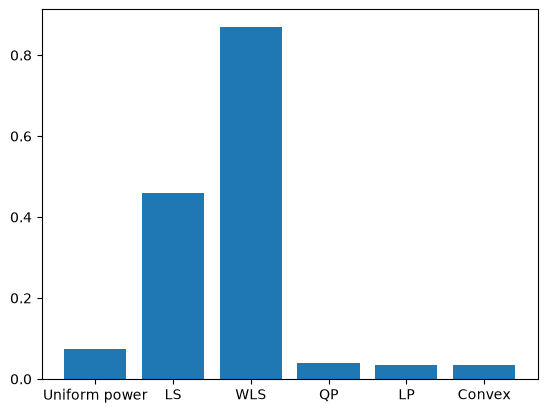

In [21]:
# Plot
names = ['Uniform power', 'LS', 'WLS', 'QP', 'LP', 'Convex']
plt.bar(names, lst_obj_values)

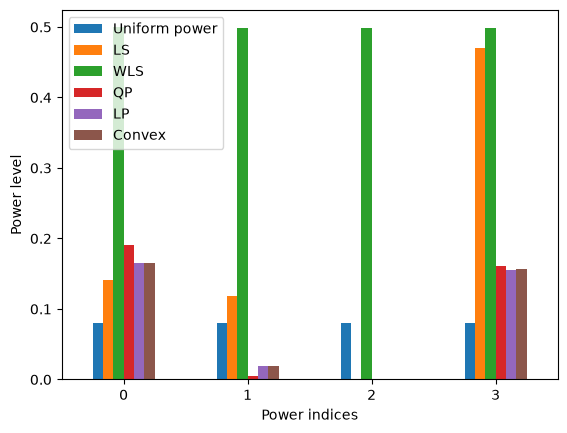

In [23]:
import pandas as pd

lst_pwrs = [power_uniform, power_least_squares, p_wls, power_least_squares_cvxpy, p_lp, p_convex]

pd.DataFrame(np.column_stack(lst_pwrs), columns=names).plot(kind='bar', rot=0)

plt.ylabel('Power level')
plt.xlabel('Power indices')
plt.show()